(300, 2)


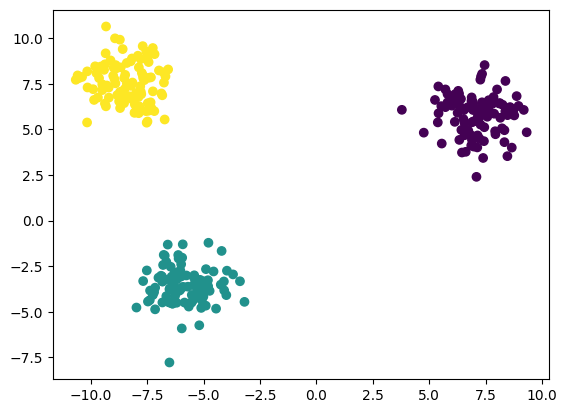

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

x,y = make_blobs(n_samples=300, n_features=2, centers=3)
print(x.shape)
# print(y)
plt.scatter(x[:,0],x[:,1],c=y)
plt.show()

Support Vector Machines - 다중 분류가 가능 하다.
분류, 회귀 및 이상 값 탐지에 사용 된다.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC

x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=43)

# C : 규제강도(값이 낮을수록 규제강도가 높아진다.)
# penalty : 규제종류(l1,l2(기본),elastic)
# dual = False(default) n_samples(샘플) > n_features(특성)
# dual = True           n_samples(샘플) < n_features(특성)
svc = LinearSVC(C=0.1,penalty='l2', dual=False).fit(x_train,y_train)

print(f'train score: {svc.score(x_train,y_train)}')
print(f'test score : {svc.score(x_test, y_test)}')

print(f'계수(coef) : {svc.coef_}')  # 기울기
print(f'절편(intercept):{svc.intercept_}') # 방향

train score: 1.0
test score : 1.0
계수(coef) : [[ 0.20031943  0.05386424]
 [-0.06779461 -0.29409389]
 [-0.13647914  0.17178885]]
절편(intercept):[-0.04844992  0.05448767 -1.19962443]


[0.20031943 0.05386424] -0.04844991964115353
[-0.06779461 -0.29409389] 0.05448766908001842
[-0.13647914  0.17178885] -1.199624429125566


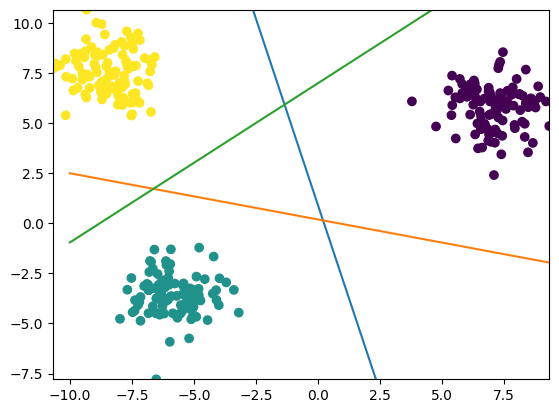

In [ ]:
import numpy as np

plt.scatter(x[:,0],x[:,1],c=y)
line = np.linspace(-10,10)

for coef,inter in zip(svc.coef_,svc.intercept_):
  print(coef,inter)
  plt.plot(line, -(line*coef[0]+inter)/coef[1]) # y = ax + b 에 의해 만들어진 공식

plt.xlim(x[:,0].min(),x[:,0].max())
plt.ylim(x[:,1].min(),x[:,1].max())
plt.show()

-(line*coef[0]+inter)/coef[1] # y=ax+b 와는 다르다?
1. 여기는 계수가 2개
2. 이렇게 계수가 여러개인 경우는 공식이 조금 달라짐
3. 계수[0] * 특성1 + 계수[1] * 특성2 + ... + 절편 = 0
4. coef[0] * x + coef[1] * y + intercept = 0
5. 우리는 y값을 구해야 하기에 나머지를 반대로 보내야 한다.(산수에서 하던거)
6. coef[1] * y  = -(coef[0] * x + intercept)
7. y  = -(coef[0] * x + intercept) / coef[1]
8. 결론적으로 plt.plot(line,-(coef[0] * x + intercept) / coef[1])